# GPU II: complete HW4.a and HW4.5 on a T4

Denisha Ketan Tank

SID4 = 8834, SEED = 8834, SLICE = 834, HP_ID = 2, CLS_A = 4, CLS_B = 6.

This is a fresh experiment notebook, not the old T4 notebook with edited scores. It is designed for one NVIDIA T4 with approximately 15 GiB usable VRAM. It records the GPU actually used and runs the full dataset slice and full training epochs. T4 mixed precision uses FP16 and loss scaling, not unsupported BF16. The FP32 baseline remains unchanged.

**In Google Colab, choose Runtime > Change runtime type > T4 GPU > Save, then Runtime > Run all.** This is a single self-contained file. Do not upload Python scripts or the dataset separately. It installs a private Python 3.11 environment without replacing Colab's kernel and downloads the exact Twitter data and both models automatically. Internet access and at least 20 GiB free disk space are needed. Linux or WSL2 Jupyter on a T4 is also supported; native Windows is not supported by vLLM.

Installation, smoke tests, data download, both assignments, reports, verification, and archiving run in order. Wait for both real-GPU smoke stages to pass before leaving the notebook running. A successful run produces a results ZIP; save this executed notebook too. No duration or accuracy is invented in advance. Colab can disconnect or reclaim the GPU: this notebook cannot guarantee an uninterrupted overnight allocation. Resuming reuses completed stages only while the same run folder and GPU remain available. Download the ZIP promptly at completion; Colab runtime files are temporary.

Part C skipped (optional).

Expected OOM probes are caught and recorded. BERT's warning about newly initialized classifier weights is also expected: those are the weights fine-tuning learns. Other failures stop with a log instead of being disguised as successful measurements. Completed stages can resume only with the same code, GPU, and settings.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import base64, gzip, hashlib, json, os, platform, shutil, subprocess, sys, time

if platform.system() != 'Linux':
    raise RuntimeError('Use Google Colab with a T4 GPU, or Linux/WSL2 Jupyter on a T4. Native Windows and macOS cannot run this vLLM CUDA notebook.')
if platform.machine().lower() not in ('x86_64', 'amd64') or not shutil.which('nvidia-smi'):
    raise RuntimeError('This notebook needs an x86-64 Linux/WSL NVIDIA GPU runtime with nvidia-smi available.')
if not any(shutil.which(name) for name in ('cc', 'gcc', 'clang')):
    raise RuntimeError('A C compiler is needed for CUDA/Triton runtime launchers. Install build-essential in Linux/WSL once, then Run All again.')
GPU_LIST = subprocess.check_output(['nvidia-smi', '-L'], text=True)
GPU_LINE = subprocess.check_output(['nvidia-smi', '--query-gpu=name,uuid,memory.total,memory.free,driver_version', '--format=csv,noheader,nounits'], text=True).splitlines()[0]
print(GPU_LIST)
print('GPU 0 name, UUID, total/free MiB, driver:', GPU_LINE)
if 'T4' not in GPU_LINE.upper():
    raise RuntimeError('This is the T4-specific notebook. In Colab choose Runtime > Change runtime type > T4 GPU > Save, then Run all. No measurements have started.')
if shutil.disk_usage(Path.cwd()).free < 20 * 2**30:
    raise RuntimeError('Free at least 20 GiB disk space before installing the CUDA environment and downloading models.')
os.environ.update({'CUDA_VISIBLE_DEVICES': '0', 'TOKENIZERS_PARALLELISM': 'false',
    'PYTHONUNBUFFERED': '1', 'MPLBACKEND': 'Agg', 'HF_HUB_DOWNLOAD_TIMEOUT': '180',
    'HF_HUB_ETAG_TIMEOUT': '60', 'VLLM_USE_V1': '0', 'GPU_ASSIGNMENT_EAGER': '1',
    'GPU_ASSIGNMENT_RESUME': '1', 'PYTORCH_NVML_BASED_CUDA_CHECK': '1',
    'VLLM_WORKER_MULTIPROC_METHOD': 'spawn', 'UV_NO_CACHE': '1',
    'OMP_NUM_THREADS': '4', 'MKL_NUM_THREADS': '4', 'OPENBLAS_NUM_THREADS': '4'})


GPU 0: Tesla T4 (UUID: GPU-07e9693f-0780-d80f-57ed-406c0604fd80)

GPU 0 name, UUID, total/free MiB, driver: Tesla T4, GPU-07e9693f-0780-d80f-57ed-406c0604fd80, 15360, 14913, 580.82.07


In [2]:
EMBEDDED_PAYLOAD = '...'
embedded = json.loads(gzip.decompress(base64.b64decode(EMBEDDED_PAYLOAD)))
gpu_identity = ','.join(part.strip() for i, part in enumerate(GPU_LINE.split(',')) if i != 3)
identity = hashlib.sha256((EMBEDDED_PAYLOAD + gpu_identity).encode()).hexdigest()
BASE = Path('/content') if Path('/content').exists() else Path.cwd()
WORK = BASE / ('GPU_II_T4_RUN_' + identity[:12])
WORK.mkdir(parents=True, exist_ok=True)
LOG = WORK / 'RUN_LOG.txt'
PYTHON = WORK / '.venv' / 'bin' / 'python'
for name, contents in embedded.items():
    path = WORK / name
    if name == 'settings.json' and path.exists():
        continue  # Preserve the common baseline batch selected by the real VRAM probe.
    path.write_text(contents, encoding='utf-8')
metadata_path = WORK / 'runtime_metadata.json'
if not metadata_path.exists():
    metadata_path.write_text(json.dumps({'started_utc': datetime.now(timezone.utc).isoformat(),
        'gpu_listing': GPU_LIST, 'gpu_start': GPU_LINE, 'platform': platform.platform(),
        'identity': identity, 'provider': 'Google Colab' if Path('/content').exists() else 'local Linux/WSL GPU runtime'}, indent=2))

def run(command, label, retries=0):
    for attempt in range(retries + 1):
        print('\n' + label + f' (attempt {attempt + 1})', flush=True)
        start = time.monotonic()
        with LOG.open('a', encoding='utf-8') as handle:
            handle.write(f'\n[{datetime.now(timezone.utc).isoformat()}] {label}\n')
            handle.write('COMMAND: ' + ' '.join(map(str, command)) + '\n')
            handle.flush()
            process = subprocess.Popen(list(map(str, command)), cwd=WORK, env=os.environ.copy(),
                stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
            for line in process.stdout:
                print(line, end='', flush=True); handle.write(line); handle.flush()
            result = process.wait()
            handle.write(f'EXIT CODE: {result}\n'); handle.flush()
        if result == 0: return time.monotonic() - start
        if attempt < retries: time.sleep(5 * (attempt + 1))
    raise RuntimeError(f'{label} failed, exit {result}. Read {LOG}. Earlier completed stages are saved; no failed stage is marked complete.')

def stage(name, command, required):
    marker = WORK / ('.complete_' + name + '.json')
    if marker.exists() and all((WORK / n).exists() for n in required):
        data = json.loads(marker.read_text())
        if data['identity'] != identity: raise RuntimeError('Refusing to reuse measurements from a different run.')
        print('Already completed, reusing:', name); return
    seconds = run(command, name, retries=1)
    missing = [n for n in required if not (WORK / n).exists()]
    if missing: raise RuntimeError(f'{name} did not create {missing}')
    marker.write_text(json.dumps({'identity': identity, 'completed_utc': datetime.now(timezone.utc).isoformat(), 'command_wall_seconds': seconds}, indent=2))

print('All run files and resumable stages will be stored in:', WORK)


All run files and resumable stages will be stored in: /content/GPU_II_T4_RUN_6ec28b7ced2a


## Install an isolated, pinned GPU environment

The notebook kernel is not replaced and does not need a restart. Python 3.11 and the GPU packages are installed in the run folder. The NVIDIA driver is a machine prerequisite, not something this notebook changes. No administrator access is used.

In [3]:
TOOLS = WORK / '.setup_tools'
if not (TOOLS / 'uv').exists():
    run([sys.executable, '-m', 'pip', 'install', '--quiet', '--target', TOOLS, 'uv==0.8.22'], 'Install uv environment manager', retries=2)
dependencies = ['vllm==0.10.2', 'torch==2.8.0', 'transformers==4.55.4',
    'bitsandbytes==0.47.0', 'accelerate==1.10.1', 'numpy==1.26.4', 'pandas==2.2.3',
    'scikit-learn==1.7.2', 'matplotlib==3.10.7', 'seaborn==0.13.2',
    'nbformat==5.10.4', 'kagglehub==0.3.13', 'ipykernel==6.30.1', 'nbconvert==7.16.6']
(WORK / 'requirements_locked.txt').write_text('\n'.join(dependencies) + '\n')
previous_path = os.environ.get('PYTHONPATH')
os.environ['PYTHONPATH'] = str(TOOLS)
try:
    if not PYTHON.exists():
        run([sys.executable, '-m', 'uv', 'venv', '--python', '3.11', WORK / '.venv'], 'Create isolated Python 3.11 environment', retries=2)
    run([sys.executable, '-m', 'uv', 'pip', 'install', '--python', PYTHON, '-r', WORK / 'requirements_locked.txt'], 'Install pinned CUDA packages', retries=2)
    versions = subprocess.check_output([sys.executable, '-m', 'uv', 'pip', 'freeze', '--python', PYTHON], text=True)
finally:
    if previous_path is None: os.environ.pop('PYTHONPATH', None)
    else: os.environ['PYTHONPATH'] = previous_path
(WORK / 'installed_versions.txt').write_text(versions)
run([PYTHON, '-c', "import torch; assert torch.cuda.is_available(), 'CUDA is not visible. Check the host NVIDIA driver and WSL GPU support.'; print('Torch:',torch.__version__,'CUDA:',torch.version.cuda,'GPU:',torch.cuda.get_device_name(0),'VRAM GiB:',torch.cuda.get_device_properties(0).total_memory/2**30)"], 'Verify the actual CUDA GPU')



Install uv environment manager (attempt 1)

Create isolated Python 3.11 environment (attempt 1)
Using CPython 3.11.17
Creating virtual environment at: .venv
Activate with: source .venv/bin/activate

Install pinned CUDA packages (attempt 1)
Resolved 209 packages in 1.39s
Prepared 209 packages in 1m 35s
Installed 209 packages in 1.45s
 + accelerate==1.10.1
 + agent-detector==2.0.0
 + aiohappyeyeballs==2.7.1
 + aiohttp==3.14.5
 + aiosignal==1.4.0
 + annotated-doc==0.0.5
 + annotated-types==0.8.0
 + anyio==4.15.1
 + astor==0.8.1
 + asttokens==3.0.2
 + attrs==26.1.0
 + beautifulsoup4==4.15.0
 + bitsandbytes==0.47.0
 + blake3==1.0.11
 + bleach==6.4.0
 + cachetools==7.2.6
 + cbor2==6.1.5
 + certifi==2026.10.23
 + cffi==2.1.1
 + charset-normalizer==3.5.2
 + click==8.5.0
 + cloudpickle==3.1.2
 + comm==0.2.3
 + compressed-tensors==0.11.0
 + contourpy==1.3.3
 + cupy-cuda12x==13.6.0
 + cycler==0.12.1
 + debugpy==1.8.22
 + defusedxml==0.7.1
 + depyf==0.19.0
 + detect-installer==0.2.1
 + dill==0.4.

9.631505929000014

## Smoke tests before expensive work

These tests use temporary synthetic data and tiny BERT weights, which are never reported as assignment results. They check forward/backward training, AMP, checkpointing, accumulation, the 8-bit optimizer, cache reuse, real vLLM timestamps for batches 1/8/32, and the real cache/scheduler interface. A dependency or API failure is caught here rather than hidden in an overnight run.

In [4]:
stage('precision_regression', [PYTHON, 'test_precision.py', '--gpu'], [])
stage('reporting_smoke', [PYTHON, 'test_reporting.py'], [])
stage('bert_smoke', [PYTHON, 'smoke_test.py', '--gpu'], [])
stage('measurement_smoke', [PYTHON, 'test_measurements.py', '--gpu'], [])
print('Both real-GPU smoke stages passed. Starting the real dataset experiments.')



precision_regression (attempt 1)
FP16 overflow: replaying the same update with loss scale 8.0
PASS: overflow replay restores dropout RNG and applies exactly the same one successful update
PASS: accumulation matches direct batches, including the short final update group
FP16 overflow: replaying the same update with loss scale 8.0
FP16 overflow: replaying the same update with loss scale 4.0
FP16 overflow: replaying the same update with loss scale 2.0
FP16 overflow: replaying the same update with loss scale 1.0
FP16 overflow: replaying the same update with loss scale 0.5
FP16 overflow: replaying the same update with loss scale 0.25
FP16 overflow: replaying the same update with loss scale 0.125
FP16 overflow: replaying the same update with loss scale 0.0625
PASS: persistent overflow stops after bounded retries without updating model weights
PRECISION REGRESSION PASSED (CPU and controlled scaler only)
FP16 overflow: replaying the same update with loss scale 8.0
PASS CUDA: real FP16 autocas

## Data preparation and common training batch

The exact same Twitter dataset hash as HW4.a is enforced. We use source rows 834–5833, seed 8834, and the same stratified 70/15/15 split for every experiment. Tokenization happens once and split indices are saved. Batch 16 is attempted first; a lower common batch is selected only if a real FP32 OOM requires it. Both assignments then use the selected baseline settings.

In [5]:
stage('data', [PYTHON, 'run_experiments.py', 'prepare'], ['cache/dataset_manifest.json', 'cache/twitter_bert_cache.pt', 'settings.json'])
settings = json.loads((WORK / 'settings.json').read_text())
manifest = json.loads((WORK / 'cache/dataset_manifest.json').read_text())
print('Selected settings:', json.dumps(settings, indent=2))
print('Dataset and split:', json.dumps(manifest, indent=2))



data (attempt 1)

  0%|          | 0.00/7.60M [00:00<?, ?B/s]
 13%|█▎        | 1.00M/7.60M [00:00<00:03, 1.98MB/s]
 39%|███▉      | 3.00M/7.60M [00:00<00:00, 5.47MB/s]
 92%|█████████▏| 7.00M/7.60M [00:00<00:00, 13.0MB/s]
100%|██████████| 7.60M/7.60M [00:00<00:00, 9.98MB/s]
Extracting files...
Copied dataset to /content/GPU_II_T4_RUN_6ec28b7ced2a/Twitter_Data.csv
{
  "dataset_name": "Twitter_Data.csv",
  "preparation_settings": {
    "model_name": "bert-base-uncased",
    "max_length": 128,
    "start_row": 834,
    "row_limit": 5000,
    "seed": 8834,
    "text_column": "clean_text",
    "label_column": "category"
  },
  "source_path": "/content/GPU_II_T4_RUN_6ec28b7ced2a/Twitter_Data.csv",
  "source_sha256": "5a7af1ec5fc749ec8e5ea13c574aeb5c06254aa1c081e3421868079d5356b3f4",
  "raw_dataset_rows": 162980,
  "requested_row_range_zero_based": [
    834,
    5833
  ],
  "requested_row_range_python": "[834:5834)",
  "selected_rows_before_cleaning": 5000,
  "excluded_source_rows_with_missi

## HW4.a: full BERT fine-tuning and first serving benchmark

BERT is trained for three full epochs with cross-entropy, AdamW, learning rate 0.00002, and sequence length 128. The notebook records losses, validation accuracy, test metrics, class errors, peak GPU allocation and wall time, then saves and reloads the classifier for two custom examples.

The second model is Qwen2.5-0.5B-Instruct. HF batch 1 and vLLM batches 1/8/32 all use FP16, identical prompt families and exactly 64 generated tokens. Each vLLM request has its own recorded completion time; the batch duration is used only for aggregate throughput.

In [6]:
stage('hw4a_training', [PYTHON, 'hw4a_training.py', '--settings', 'settings.json'],
    ['outputs/hw4a_training_summary.json', 'checkpoints/hw4a_bert_classifier/model.safetensors', 'outputs/hw4a_learning_curves.png'])
stage('hw4a_serving', [PYTHON, 'accurate_serving.py', 'benchmark', '--prefix', 'hw4a_'],
    ['outputs/hw4a_serving_summary.json', 'outputs/hw4a_request_timings.csv'])
print('HW4.a training and serving stages finished.')



hw4a_training (attempt 1)
Using frozen tokenized data and split indices from /content/GPU_II_T4_RUN_6ec28b7ced2a/cache/twitter_bert_cache.pt
Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
{"epoch": 1, "training_loss": 0.9082491632870265, "validation_loss": 0.6851405286788941, "validation_accuracy": 0.716, "training_seconds": 75.33056312999997, "throughput_samples_per_second": 46.46188551597518}
{"epoch": 2, "training_loss": 0.5243684139251709, "validation_loss": 0.5201753527323405, "validation_accuracy": 0.808, "training_seconds": 79.39262257999997, "throughput_samples_per_second": 44.08470064675374}
{"epoch": 3, "training_loss": 0.2898897445627621, "validation_loss": 0.5093885046641032, "validation_accuracy": 0.824, "training_seconds": 82.458

## HW4.5 Parts A and B: memory walls and training comparisons

First, each memory technique is tested independently at power-of-two batch sizes until a real OOM. Up to the training-set size, successful points are full training epochs. Larger capacity-only probes repeat existing training rows to materialize the entire requested physical batch for one real forward/backward/optimizer update. These are labelled separately, never used for accuracy, and never called full epochs. Final quality runs use the largest successful power-of-two batch that fits the original training split and train for three full epochs.

Next, a separate controlled comparison trains all techniques with the same effective batch, examples, three epochs, seed, and optimizer-update budget. Accumulation uses a smaller physical batch. AMP uses T4-compatible FP16 with conservative loss scaling; it does not request BF16. A recoverable FP16 overflow replays the same logical update with a lower loss scale and restored dropout RNG; weights and update counts change only after a successful update. Retries and their actual execution costs are recorded. Persistent numerical failure stops rather than being hidden. This is the fair quality comparison; changing the maximum batch does not masquerade as a technique-only accuracy effect. The existing baseline is reused when it is exactly the same experiment.

In [7]:
stage('hw45_training', [PYTHON, 'hw45_training.py', 'all', '--settings', 'settings.json'],
    ['outputs/training_summary.json', 'outputs/batch_scaling.csv', 'outputs/technique_comparison.csv'])
stage('controlled_training', [PYTHON, 'run_experiments.py', 'controlled'], ['outputs/controlled_training.json'])
print('All full-epoch memory probes, maximum-batch fine-tunes, and controlled fine-tunes finished.')



hw45_training (attempt 1)
Using frozen tokenized data and split indices from /content/GPU_II_T4_RUN_6ec28b7ced2a/cache/twitter_bert_cache.pt

Probing baseline batch=16
Reusing completed probe from this run.
success 

Probing baseline batch=32
success 

Probing baseline batch=64
success 

Probing baseline batch=128
success 

Probing baseline batch=256
oom CUDA out of memory. Tried to allocate 96.00 MiB. GPU 0 has a total capacity of 14.56 GiB of which 25.81 MiB is free. Including non-PyTorch memory, this process has 14.54 GiB memory in use. Of the allocated memory 14.38 GiB is allocated by PyTorch, and 34.13 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://pytorch.org/docs/stable/notes/cuda.html#environment-variables)

Probing mixed_precision batch=16
success 

Probing mixed_precision batch=32
success 

Probing mi

## Part C

Part C skipped (optional).

## Part D: repeated serving and observed KV-cache capacity

The serving benchmark is repeated with the same model, precision, prompt families, output length, and per-request timing definition. There are at least 100 requests per configuration and at least 20 measured vLLM batches per batch size, after warm-up.

Context probes use fresh GPU processes. Actual cache tensor storage and scheduler block occupancy are measured. Success requires eight full prompts to reside together; serial completion of eight queued requests is not called simultaneous batch-8 capacity. The maximum supported model length is never silently extended. Memory exhaustion, a cache allocation limit, admission pressure, and a model-position ceiling are distinguished. A failing capacity bracket is refined to within 128 prompt tokens, not mislabelled as an exact one-token threshold.

In [8]:
stage('hw45_serving', [PYTHON, 'accurate_serving.py', 'benchmark'], ['outputs/serving_summary.json', 'outputs/request_timings.csv'])
stage('context_capacity', [PYTHON, 'accurate_serving.py', 'context'], ['outputs/context_summary.json', 'outputs/kv_cache_context.csv'])
subprocess.run(['nvidia-smi', '-L'], stdout=(WORK / 'outputs/gpu_uuid_after.txt').open('w'), check=True, text=True)
print('Repeated serving and observed context-capacity measurements finished.')



hw45_serving (attempt 1)
Device set to use cuda:0
The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are no

## Findings, comparisons, and figures

The reports below are generated from this run's measurements. All four independent techniques are ranked using the matched-budget controls. Configuration recommendations use validation accuracy, not repeated tuning on test accuracy. Error diagnoses are cautious interpretations of the actual misclassified tweets; read them before submitting work in your own name.


Generate findings and verify real measured artifacts (attempt 1)
PASS: same dataset hash
PASS: same preparation settings
PASS: exact source rows
PASS: fixed split
PASS: all independent and combined memory sweeps reached OOM
PASS: successful probes materialized their requested batch
PASS: quality runs never repeat rows to inflate a physical batch
PASS: six matched training conditions
PASS: same controlled effective batch and training updates
PASS: saved BERT reloaded
PASS: five original worst-class mistakes
PASS: baseline and repeated serving configurations match
PASS: serving batches recorded in both stages
PASS: each serving row has at least 100 real request samples
PASS: at least 20 measured vLLM batches per shape
PASS: request timestamps, not batch copies
PASS: eight concurrent KV allocations observed
PASS: capacity boundary or unmodified model limit identified
PASS: checkpoint weights and tokenizer exist
PASS: both GPU UUID captures exist
PASS: all required figures exist
PASS: opt

# HW4.a: BERT sentiment and serving

Student: Denisha Ketan Tank

SID4 = 8834, SEED = 8834, SLICE = 834, HP_ID = 2, CLS_A = 4, CLS_B = 6.

Actual GPU: Tesla T4; UUID: `GPU-07e9693f-0780-d80f-57ed-406c0604fd80`; VRAM: 15.00 GiB; driver: 580.82.07; PyTorch CUDA: 12.8.

Dataset: Kaggle saurabhshahane/twitter-sentiment-dataset, Twitter_Data.csv. Zero-based rows 834 through 5833 inclusive, Python slice [834:5834). SHA-256: `5a7af1ec5fc749ec8e5ea13c574aeb5c06254aa1c081e3421868079d5356b3f4`. The fixed SEED 8834 stratified split is 3,500/750/750. Every comparison reuses these exact saved split indices.

Memory is reported in binary GiB. Peak allocated training memory, total GPU-process usage, reserved cache storage, and actively occupied cache blocks are different measurements.

Training parameters remain FP32. AMP uses T4-compatible FP16 with conservative loss scaling; the actual autocast dtype is saved in each result. T4 does not support native BF16 or TF32. A recoverable overflow repeats the same logical update at lower scale, restores dropout RNG, and changes no weights until successful. The repeat cost stays in measured time and memory, and overflow retry counts are saved in the raw results. Persistent numerical failure stops instead of being called a successful update.

Accuracy columns in the tables are fractions from 0 to 1. Dataset labels -1, 0, and 1 mean negative, neutral, and positive sentiment.

## BERT results

The original model used batch 16, sequence length 128, learning rate 0.00002, and three full epochs. Test accuracy was 83.60%. Training plus validation took 255.65 seconds, with 2.466 GiB peak training allocation.

The best validation accuracy occurred at epoch 3. The best point was the final epoch, so no later training cost is claimed.

| epoch | training_loss | validation_loss | validation_accuracy | training_seconds |
|---|---|---|---|---|
| 1 | 0.9082 | 0.6851 | 0.7160 | 75.3306 |
| 2 | 0.5244 | 0.5202 | 0.8080 | 79.3926 |
| 3 | 0.2899 | 0.5094 | 0.8240 | 82.4588 |

![Training and validation curves](outputs/hw4a_learning_curves.png)

| class_label | precision | recall | support |
|---|---|---|---|
| -1.0 | 0.7151 | 0.7665 | 167 |
| 0.0 | 0.8294 | 0.9000 | 270 |
| 1.0 | 0.9209 | 0.8179 | 313 |

![Confusion matrix](outputs/hw4a_confusion_matrix.png)

The lowest-recall class was -1.0. The following are actual errors from that class. The diagnoses discuss wording, not proven internal model mechanisms.

| source_row | true_class | predicted_class | text | diagnosis |
|---|---|---|---|---|
| 1667 | -1.0 | 1.0 | ratan naval tata family patriarch the billion tata empire has lavished praise prime minister narendra modi underscoring that his leadership what the country needsat this point time and urging citizens rally round his vision create new india | The wording includes leadership, praise; that may explain the prediction 1.0, while the recorded label is -1.0. Missing context or label noise should be considered before assuming the annotation is unambiguous. |
| 3127 | -1.0 | 1.0 | from rahul gandhis fake promise today from where will bring money this much money india than according him modi government failure and chowkidar chor than more than this money was india before five years than why not thought this  | The wording includes chor, failure, fake, but the prediction is 1.0; those critical cues are not reflected in the output. This is a text-based diagnosis, not proof of the model's internal cause. |
| 4326 | -1.0 | 0.0 | talk about looting hypocrite modi took white money converted black gave trolls everone knows who else | The wording includes hypocrite, looting, trolls, but the prediction is 0.0; those critical cues are not reflected in the output. This is a text-based diagnosis, not proof of the model's internal cause. |
| 5127 | -1.0 | 0.0 | took you hrs raju finally break silence this did you spend them thinking how you will bring modi into this without appearing monkey balancing that case you wasted that time | The wording includes wasted, but the prediction is 0.0; those critical cues are not reflected in the output. This is a text-based diagnosis, not proof of the model's internal cause. |
| 4162 | -1.0 | 1.0 | bullshit congressmen india controlled remote whose controller italian converted parsi claiming herself citizen the countrywhich only documents not her heart her name sonia ghandyif the hindusmuslimsetcwant goodthen vote only modi | The wording includes bullshit, but the prediction is 1.0; those critical cues are not reflected in the output. This is a text-based diagnosis, not proof of the model's internal cause. |

## Saved model and custom inference

The classifier and tokenizer were saved and reloaded before these two predictions.

| text | predicted_class | confidence |
|---|---|---|
| The movie was thoughtful, funny, and much better than I expected. | 1.0 | 0.9576 |
| The story dragged for hours and the ending was disappointing. | -1.0 | 0.9301 |

## HF and vLLM serving

HF pipeline wall time for each batch-1 request; vLLM individual finished_time minus client submission time, including tokenization, admission, and queue time. Each request has its own completion timestamp; engine arrival_time is also saved.

Each mode generates exactly 64 new tokens, is warmed up, and uses the same raw prompt family and FP16 model. Each row has at least 100 real requests. vLLM batches have at least 20 measured repetitions. Individual request timestamps and raw observations are saved, so requests are not all assigned the enclosing batch time.

| configuration | tokens_per_second | p50_latency_ms | p95_latency_ms | requests_measured | measured_batches |
|---|---|---|---|---|---|
| HF pipeline, batch 1 | 29.9178 | 2132.9225 | 2201.3567 | 100 | 100 |
| vLLM, batch 1 | 66.3984 | 962.0703 | 1006.2642 | 100 | 100 |
| vLLM, batch 8 | 494.9773 | 1029.8672 | 1086.2345 | 160 | 20 |
| vLLM, batch 32 | 1660.8614 | 1228.0576 | 1274.3907 | 640 | 20 |

No tested batch showed worse median request latency than HF while throughput was still increasing. Batching can finish more tokens per second even when individual requests wait longer. For an interactive chatbot I would prioritize request latency, especially p95. For offline generation, total throughput is usually more important.

### My prompts and actual generated answers

| configuration | prompt | answer |
|---|---|---|
| HF pipeline, batch 1 | Explain why batching can improve GPU throughput in two sentences. |  Batching allows multiple data points to be processed together, reducing the time and energy required for each individual operation, thereby increasing overall processing speed and efficiency. Additionally, it enables parallelization of tasks across multiple GPUs, allowing for faster computation by utilizing the collective computational power of all available GPUs rather than relying on a single core or |
| HF pipeline, batch 1 | Describe one benefit and one cost of mixed precision training. |  One benefit of mixed precision training is that it allows for more accurate predictions, as the model can handle larger numbers of parameters and operations efficiently. This can lead to faster training times and improved performance on certain tasks.  One cost associated with mixed precision training is that it requires additional computational resources and memory to store and manipulate the data |
| vLLM, batch 1 | Explain why batching can improve GPU throughput in two sentences. |  Batching can improve GPU throughput by allowing multiple data sets to be processed simultaneously, reducing the time required to complete a task, and increasing the overall efficiency of the computation. Additionally, batching can help to minimize memory usage and improve the performance of the GPU by reducing the amount of data that needs to be transferred between the CPU |
| vLLM, batch 8 | Explain why batching can improve GPU throughput in two sentences. |  Batching can improve GPU throughput by allowing multiple data sets to be processed simultaneously, reducing the time required to complete a task, and increasing the overall efficiency of the computation. Additionally, batching can help to minimize memory usage and improve the performance of the GPU by reducing the amount of data that needs to be transferred between the CPU |
| vLLM, batch 32 | Explain why batching can improve GPU throughput in two sentences. |  Batching can improve GPU throughput by allowing multiple data sets to be processed simultaneously, reducing the time required to complete a task, and increasing the overall efficiency of the computation. Additionally, batching can help to minimize memory usage and improve the performance of the GPU by reducing the amount of data that needs to be transferred between the CPU |



# HW4.5: throughput, memory, and serving

Student: Denisha Ketan Tank

SID4 = 8834, SEED = 8834, SLICE = 834, HP_ID = 2, CLS_A = 4, CLS_B = 6.

Actual GPU: Tesla T4; UUID: `GPU-07e9693f-0780-d80f-57ed-406c0604fd80`; VRAM: 15.00 GiB; driver: 580.82.07; PyTorch CUDA: 12.8.

Dataset: Kaggle saurabhshahane/twitter-sentiment-dataset, Twitter_Data.csv. Zero-based rows 834 through 5833 inclusive, Python slice [834:5834). SHA-256: `5a7af1ec5fc749ec8e5ea13c574aeb5c06254aa1c081e3421868079d5356b3f4`. The fixed SEED 8834 stratified split is 3,500/750/750. Every comparison reuses these exact saved split indices.

Memory is reported in binary GiB. Peak allocated training memory, total GPU-process usage, reserved cache storage, and actively occupied cache blocks are different measurements.

Training parameters remain FP32. AMP uses T4-compatible FP16 with conservative loss scaling; the actual autocast dtype is saved in each result. T4 does not support native BF16 or TF32. A recoverable overflow repeats the same logical update at lower scale, restores dropout RNG, and changes no weights until successful. The repeat cost stays in measured time and memory, and overflow retry counts are saved in the raw results. Persistent numerical failure stops instead of being called a successful update.

Accuracy columns in the tables are fractions from 0 to 1. Dataset labels -1, 0, and 1 mean negative, neutral, and positive sentiment.

## Part A: batch scaling

The clarification permits one GPU, so no second-card result or VRAM ratio is invented. Probes up to the training-set size are complete seeded one-epoch runs. Larger probes repeat training rows for one full physical-batch optimizer update solely to find the memory wall. They are explicitly labelled capacity-only, not used for accuracy or the epoch-throughput plateau. A fresh process is used after every attempt, including the expected OOM.

| physical_batch | status | measurement_kind | throughput_samples_per_second | peak_memory_allocated_gb | mean_time_per_epoch_seconds |
|---|---|---|---|---|---|
| 16 | success | full_training_epoch | 50.0468 | 2.4657 | 69.9346 |
| 32 | success | full_training_epoch | 49.3244 | 3.7140 | 70.9588 |
| 64 | success | full_training_epoch | 48.0712 | 6.0640 | 72.8086 |
| 128 | success | full_training_epoch | 46.8989 | 10.8660 | 74.6285 |
| 256 | oom | not measured | not measured | not measured | not measured |

The largest successful FP32 batch was 128. The first incremental throughput gain below 5% occurred at batch 32; this is the stated plateau rule.

![Batch scaling](outputs/batch_size_throughput.png)

## Part B: maximum-batch experiments

| technique | physical_batch | effective_batch | optimizer_steps | throughput_samples_per_second | peak_memory_allocated_gb | test_accuracy |
|---|---|---|---|---|---|---|
| baseline | 128 | 128 | 84 | 45.2084 | 10.8660 | 0.6800 |
| mixed_precision | 256 | 256 | 42 | 189.8607 | 13.9182 | 0.6067 |
| gradient_checkpointing | 512 | 512 | 21 | 33.9665 | 7.5712 | 0.5627 |
| optimizer_8bit | 128 | 128 | 84 | 45.2866 | 10.2491 | 0.6800 |
| best_combination | 256 | 256 | 42 | 190.5405 | 13.2993 | 0.6053 |
| gradient_accumulation | 16 | 128 | 84 | 44.4754 | 2.8807 | 0.6640 |

Each quality configuration was trained for three full epochs at the largest successful power-of-two batch that does not exceed the original training split. Larger capacity-only memory limits are listed below, not claimed as quality-training batch sizes. Changing batch size changes optimizer-update counts, so these accuracy differences cannot be assigned solely to a technique.

| technique | memory_capacity_batch | quality_training_batch |
|---|---|---|
| baseline | 128 | 128 |
| mixed_precision | 256 | 256 |
| gradient_checkpointing | 512 | 512 |
| optimizer_8bit | 128 | 128 |
| best_combination | 256 | 256 |

## Part B: matched-budget quality and memory controls

| technique | physical_batch | effective_batch | optimizer_steps | throughput_samples_per_second | peak_memory_allocated_gb | test_accuracy |
|---|---|---|---|---|---|---|
| baseline | 16 | 16 | 657 | 44.2698 | 2.4657 | 0.8360 |
| mixed_precision | 16 | 16 | 657 | 126.7957 | 2.2424 | 0.8307 |
| gradient_checkpointing | 16 | 16 | 657 | 30.7502 | 1.6812 | 0.8360 |
| optimizer_8bit | 16 | 16 | 657 | 41.1716 | 1.8642 | 0.8267 |
| best_combination | 16 | 16 | 657 | 122.4189 | 1.6196 | 0.8267 |
| gradient_accumulation | 4 | 16 | 657 | 38.5309 | 1.9987 | 0.8280 |

All six controls use effective batch 16, 657 optimizer updates, 10500 examples, and three epochs. Accumulation intentionally uses a smaller physical batch with the same effective batch. Data order, initialization seed, learning rate, and examples are fixed. Dropout and floating-point arithmetic can still produce differences, so a single run does not establish statistical significance.

![Controlled losses](outputs/controlled_losses.png)

### Four independent techniques ranked by memory saved per throughput lost

| rank | technique | memory_saved_GiB | throughput_change | GiB_saved_per_sample_per_second_lost |
|---|---|---|---|---|
| 1 | mixed_precision | 0.2233 | 82.5259 | no throughput loss |
| 2 | optimizer_8bit | 0.6015 | -3.0982 | 0.1942 |
| 3 | gradient_accumulation | 0.4670 | -5.7389 | 0.0814 |
| 4 | gradient_checkpointing | 0.7845 | -13.5196 | 0.0580 |

The combined candidate is excluded from the independent ranking. A speedup with a memory saving has no positive throughput-loss denominator; a technique that saves no memory is labelled accordingly.

Checkpointing changed matched-batch throughput by -30.5%. The extra backward recomputation explains why memory savings may have a speed cost; the measured sign is reported even if a short run is noisy.

Matched accumulation used physical batch 4 times 4 accumulation steps. Its time to the same 657 updates was 293.00 seconds, versus 255.65 seconds for the direct batch.

I would first consider mixed_precision from this ranking, while checking its measured validation accuracy. On a 32 GiB card I would not add checkpointing if the required batch already fits and the measured recomputation cost is not worthwhile. That 32 GiB statement is a recommendation, not a second-GPU experiment.

## Part C

Part C skipped (optional)

## Part D: serving repeated on the same GPU

HF pipeline wall time for each batch-1 request; vLLM individual finished_time minus client submission time, including tokenization, admission, and queue time. Each request has its own completion timestamp; engine arrival_time is also saved.

| configuration | tokens_per_second | p50_latency_ms | p95_latency_ms | requests_measured | measured_batches |
|---|---|---|---|---|---|
| HF pipeline, batch 1 | 29.8835 | 2119.8545 | 2222.8503 | 100 | 100 |
| vLLM, batch 1 | 67.4744 | 945.5202 | 996.6970 | 100 | 100 |
| vLLM, batch 8 | 501.2639 | 1012.9035 | 1068.5880 | 160 | 20 |
| vLLM, batch 32 | 1690.8808 | 1203.5182 | 1253.8559 | 640 | 20 |

No tested batch showed worse median request latency than HF while throughput was still increasing. Batching can finish more tokens per second even when individual requests wait longer. For an interactive chatbot I would prioritize request latency, especially p95. For offline generation, total throughput is usually more important.

The request samples within a batch can be correlated. More measured requests improve quantile resolution, but these results are still a benchmark under this workload, not a production p95 guarantee.

| configuration | HW4a_tokens_s | HW45_tokens_s | HW4a_p50_ms | HW45_p50_ms | HW4a_p95_ms | HW45_p95_ms |
|---|---|---|---|---|---|---|
| HF pipeline, batch 1 | 29.9178 | 29.8835 | 2132.9225 | 2119.8545 | 2201.3567 | 2222.8503 |
| vLLM, batch 1 | 66.3984 | 67.4744 | 962.0703 | 945.5202 | 1006.2642 | 996.6970 |
| vLLM, batch 8 | 494.9773 | 501.2639 | 1029.8672 | 1012.9035 | 1086.2345 | 1068.5880 |
| vLLM, batch 32 | 1660.8614 | 1690.8808 | 1228.0576 | 1203.5182 | 1274.3907 | 1253.8559 |

Both stages used the same GPU and weights, FP16, 64 output tokens, individual-request timing, and frozen GPU-memory budget (0.8000 of total VRAM). Background load and GPU clock/temperature may contribute to timing changes; no hardware upgrade is claimed. The actual cache-pool allocation is saved separately in each serving summary.

### Observed KV-cache usage and simultaneous batch-8 capacity

Cache-pool bytes come from the actual GPU tensor storages. Peak occupied blocks are observed after scheduler allocation and before model execution. Multiplying the observed occupied blocks by measured bytes per block gives the active reserved KV storage, including block rounding. This is not an isolated before/after nvidia-smi estimate. Prefix caching and chunked prefill are disabled for the capacity probes, and success requires all eight full prompts to reside together.

| context_length | status | cache_pool_bytes | peak_used_cache_blocks | measured_active_kv_bytes | peak_running_requests |
|---|---|---|---|---|---|
| 1 | success | 11393433600 | 8 | 1572864 | 8 |
| 128 | success | 11391467520 | 64 | 12582912 | 8 |
| 256 | success | 11378688000 | 128 | 25165824 | 8 |
| 512 | success | 11305549824 | 256 | 50331648 | 8 |
| 1024 | success | 11156520960 | 512 | 100663296 | 8 |
| 2048 | success | 10858659840 | 1024 | 201326592 | 8 |
| 4096 | success | 10262544384 | 2048 | 402653184 | 8 |
| 8192 | success | 9070706688 | 4096 | 805306368 | 8 |
| 16384 | success | 6686638080 | 8192 | 1610612736 | 8 |
| 24560 | success | 4305715200 | 12280 | 2414346240 | 8 |
| 28656 | success | 3114074112 | 14328 | 2816999424 | 8 |
| 29168 | success | 2966028288 | 14584 | 2867331072 | 8 |
| 29296 | success | 2929262592 | 14648 | 2879913984 | 8 |
| 29424 | batch8_admission_limit | 2891317248 | 12873 | 2530934784 | 7 |
| 29680 | batch8_admission_limit | 2816212992 | 12985 | 2552954880 | 7 |
| 30704 | batch8_admission_limit | 2518155264 | 11514 | 2263744512 | 6 |
| 32767 | batch8_admission_limit | 1918894080 | 8192 | 1610612736 | 4 |

The longest verified simultaneous batch-8 prompt was 29296 tokens per request. The limiting category was batch8_admission_limit. The successful/failing bracket ends at 29424 and is at most 128 tokens wide; an exact one-token boundary is not claimed.

Each probe provisions a simultaneous eight-request prefill and max_model_len=prompt_length+1, in a fresh V0 engine. The resulting reserved cache pool is measured separately for each configuration. This is an engine-configuration capacity bracket, not a universal hardware-only OOM boundary.

CUDA OOM, an engine cache-allocation limit, and inability to admit eight full contexts are recorded separately. A non-memory exception stops the run rather than being relabelled as an OOM.

## Part E: configuration and GPU-hours

My validation-based choice among the matched controls is baseline. I selected the highest-throughput option whose final validation accuracy was within one percentage point of the matched FP32 baseline, rather than tuning on test accuracy. Its measured training allocation was 2.466 GiB, throughput 44.27 samples/s, wall time 255.65 seconds, and test accuracy 83.60%.

One full fine-tune under that measured configuration used 1 GPU × 255.65 seconds / 3600 = 0.0710 GPU-hours. This excludes setup and the other experimental conditions.

### HW4.5 summary

Selected matched-budget configuration: baseline; 2.466 GiB peak, 44.27 samples/s, 255.65 seconds. It is an HW4.5 result, not an HW5 baseline.



# AI-use appendix

I used an AI assistant for the experimental code, notebook organization, smoke tests, and result-report generation. The measurements in this folder come from my T4 run, not from an estimated GPU score.

A specific error in the earlier benchmark was this latency calculation:

```python
latencies_ms.extend([elapsed * 1000] * batch_size)
```

This assigns a single batch duration to every request and does not measure each request finishing independently. The assistant found this during a source-code audit. The new benchmark uses each request's own finished_time relative to client submission, also saves its arrival_time, and stores the raw observations. It warms each batch shape and measures more repetitions.

The earlier quality comparison also changed batch size and optimizer-update count at once. The new run keeps a separate three-epoch, matched-effective-batch comparison for all four techniques and the combined candidate. Tests check that update counts and sample counts actually match.

The assistant also replaced theoretical-only active KV estimates with actual cache tensor-storage and scheduler-block observations. Non-capacity errors are not hidden as OOM. I still need to understand and review the generated findings before submitting them as my work.


# GPU-hour record

Actual GPU: Tesla T4 (GPU-07e9693f-0780-d80f-57ed-406c0604fd80).

Chosen configuration: baseline. One GPU × 255.648288 seconds / 3600 = 0.071013 GPU-hours.

Original HW4.a baseline: 0.071013 GPU-hours.

These are training-plus-validation costs for individual three-epoch runs, not total allocation time for all experiments.


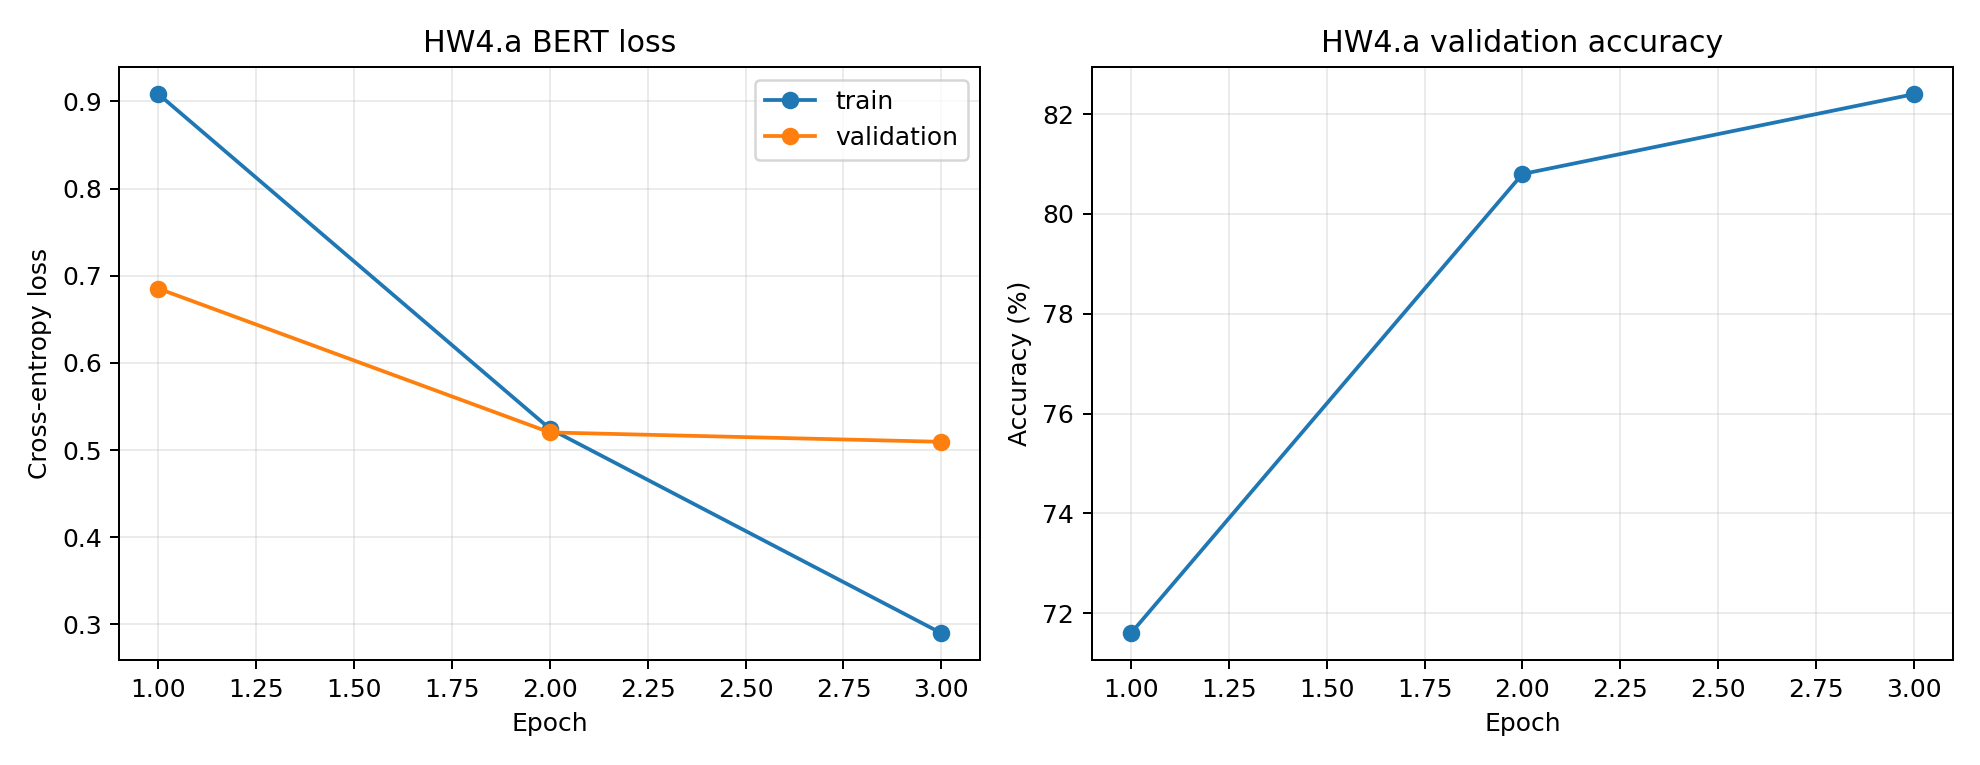

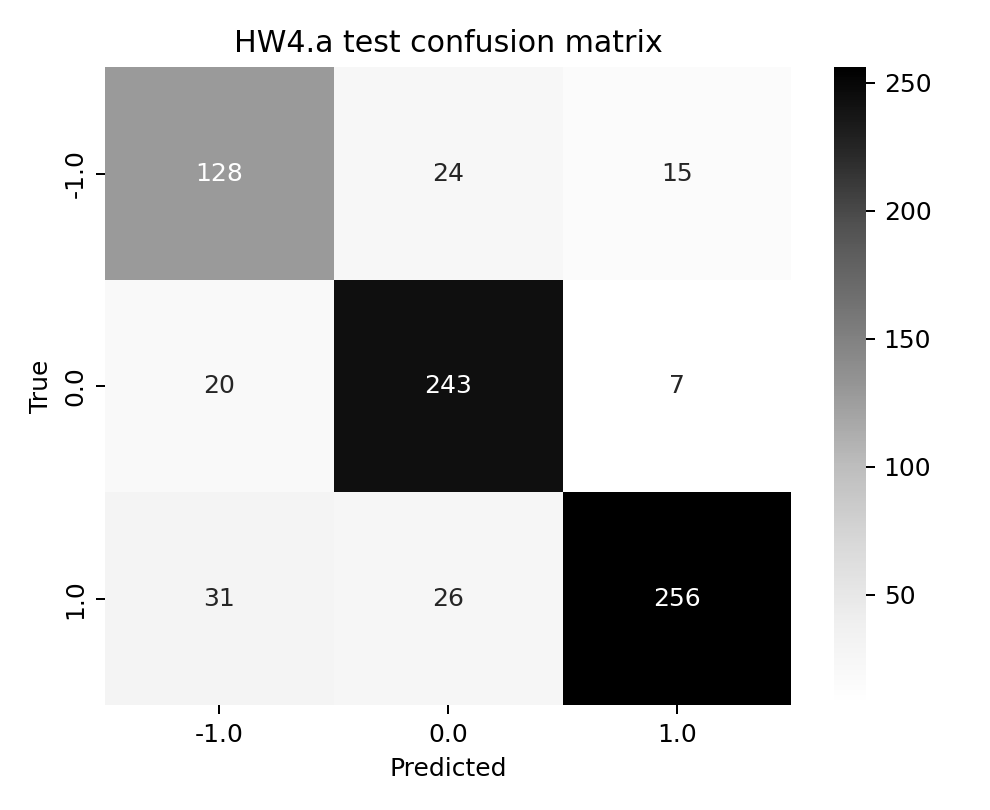

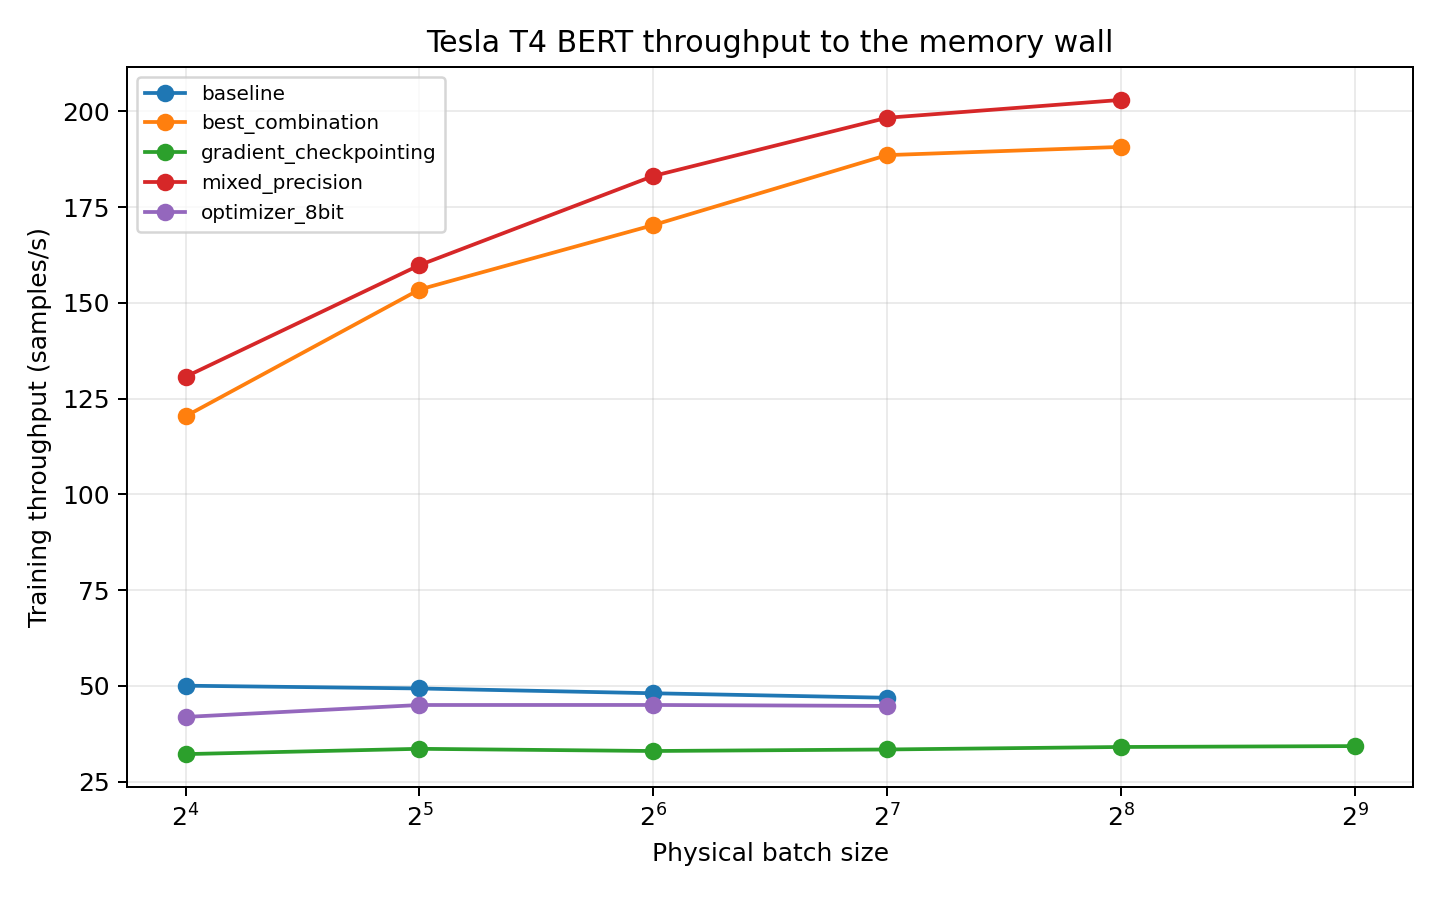

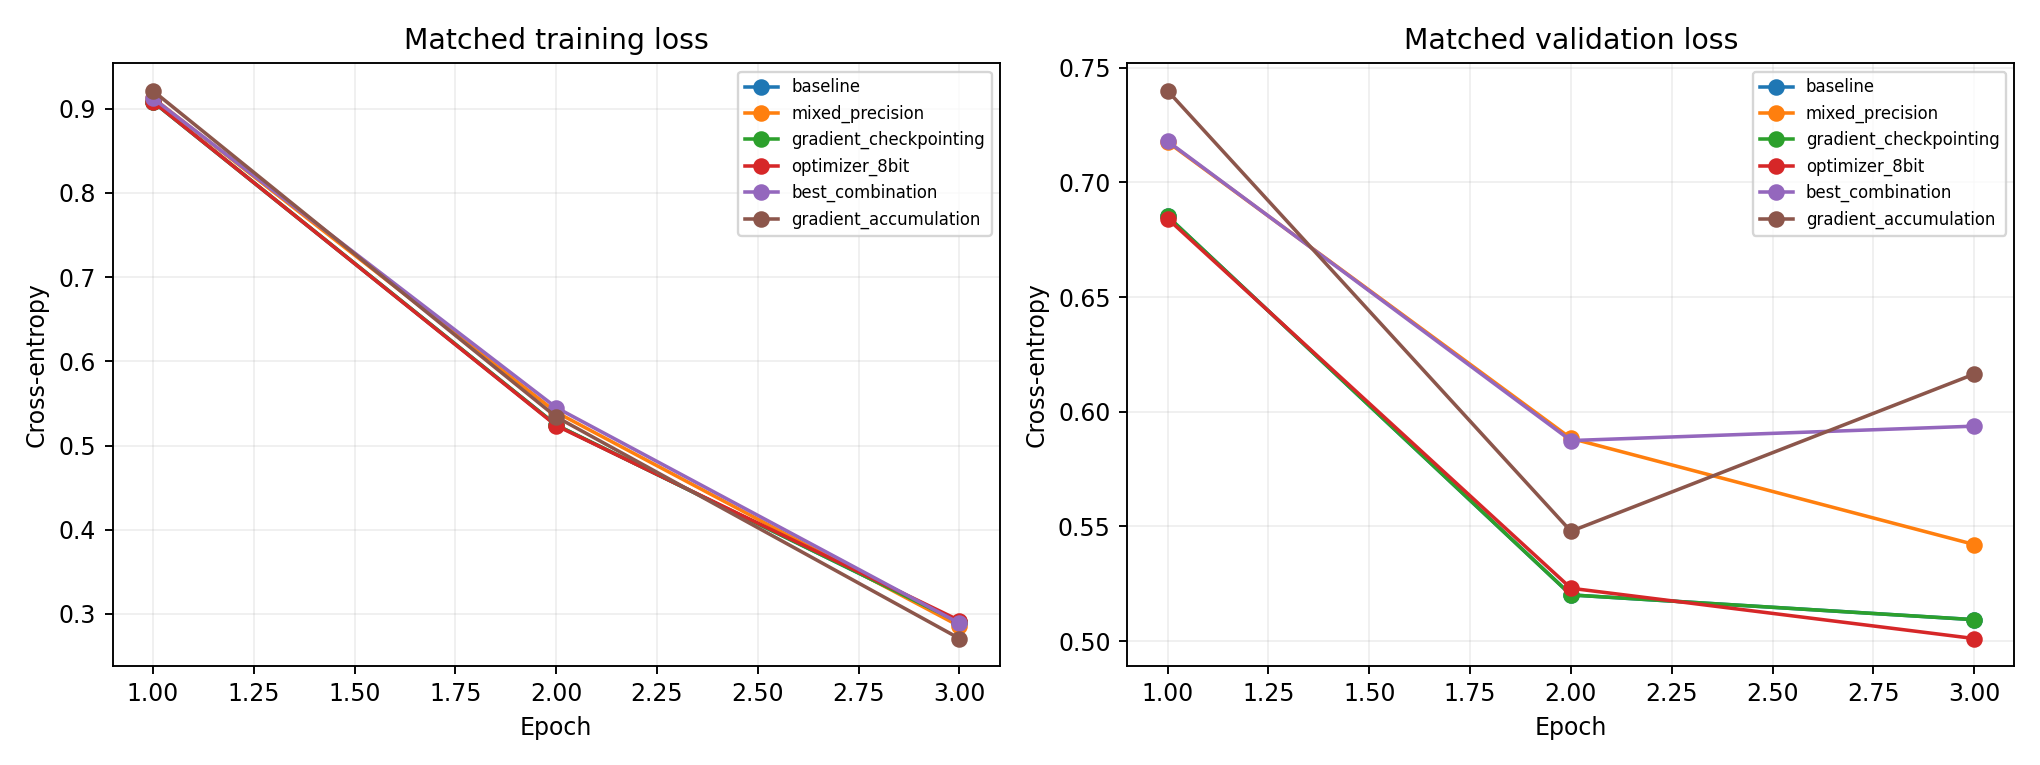

In [9]:
run([PYTHON, 'make_reports.py'], 'Generate findings and verify real measured artifacts')
from IPython.display import display, Markdown, Image
for name in ['HW4A_METRICS.md', 'METRICS.md', 'AI_USE.md', 'GPU_HOURS.md']:
    display(Markdown((WORK / name).read_text()))
for name in ['hw4a_learning_curves.png', 'hw4a_confusion_matrix.png', 'batch_size_throughput.png', 'controlled_losses.png']:
    display(Image(filename=str(WORK / 'outputs' / name)))


## Verify and package everything

The archive contains the full BERT checkpoint and tokenizer, source code, locked environment versions, dataset manifest and split cache, raw request timings, context-probe logs, plots, reports, GPU UUID captures, and the timestamped console log. It excludes the installed environment and downloaded package caches.

This does not upload anything, create a GitHub tag, invent a lab reservation, or change repository visibility. Save this executed notebook after completion. The large ZIP and the executed notebook are the files to return for the final audit and repository publication.

In [10]:
verification = json.loads((WORK / 'outputs/verification.json').read_text())
assert verification['all_passed'], 'Keep the log: a measured-artifact verification did not pass.'
metadata = json.loads(metadata_path.read_text())
completed = datetime.now(timezone.utc)
elapsed = (completed - datetime.fromisoformat(metadata['started_utc'])).total_seconds()
(WORK / 'RESERVATION_RECORD.md').write_text(
    '# Actual runtime record\n\nProvider: ' + metadata['provider'] + '\n\n' + GPU_LIST +
    '\nRun started (UTC): ' + metadata['started_utc'] + '\n\nRun completed (UTC): ' + completed.isoformat() +
    '\n\nElapsed session wall time, including setup, downloads, and possible idle/resume intervals: ' + str(round(elapsed, 2)) + ' seconds.\n\n' +
    'No lab booking is invented. A personal/hosted GPU does not need a lab reservation; if this was a reserved lab system, add its actual booking confirmation before submission.\n')
shutil.copy2(LOG, WORK / 'RUN_LOG_HW4A.txt')
(WORK / 'RUN_IDENTITY.json').write_text(json.dumps({'identity': identity, 'completed_utc': completed.isoformat(), 'gpu': GPU_LIST}, indent=2))
import zipfile
archive = BASE / ('GPU_II_T4_RESULTS_' + identity[:12] + '.zip')
excluded = {'.venv', '.setup_tools', '__pycache__', '.ipynb_checkpoints', '.git'}
with zipfile.ZipFile(archive, 'w', compression=zipfile.ZIP_DEFLATED, compresslevel=1, allowZip64=True) as bundle:
    for path in WORK.rglob('*'):
        relative = path.relative_to(WORK)
        if path.is_file() and not any(part in excluded for part in relative.parts):
            bundle.write(path, Path('gpu-ii') / relative)
with zipfile.ZipFile(archive) as bundle:
    bad = bundle.testzip()
    assert bad is None, 'Archive integrity failure: ' + str(bad)
print('MEASURED EXPERIMENTS AND ARTIFACT CHECKS PASSED')
print('Actual GPU:', GPU_LIST.strip())
print('Results archive:', archive)
print('Archive size MiB:', round(archive.stat().st_size / 2**20, 1))
print('SAVE THIS EXECUTED NOTEBOOK as well. Then return the notebook and archive for the final audit/upload.')
try:
    from google.colab import files
except ImportError:
    from IPython.display import FileLink
    display(FileLink(str(archive.relative_to(Path.cwd()))))
else:
    try: files.download(str(archive))
    except Exception as error: print('Automatic browser download was unavailable:', str(error), '\nThe archive remains at', archive)


MEASURED EXPERIMENTS AND ARTIFACT CHECKS PASSED
Actual GPU: GPU 0: Tesla T4 (UUID: GPU-07e9693f-0780-d80f-57ed-406c0604fd80)
Results archive: /content/GPU_II_T4_RESULTS_6ec28b7ced2a.zip
Archive size MiB: 398.8
SAVE THIS EXECUTED NOTEBOOK as well. Then return the notebook and archive for the final audit/upload.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Post-run publication notes, October 28, 2026

The ten executed code cells, their execution counts and their outputs are unchanged. No training or benchmark was rerun for these edits. The original notebook and results ZIP are preserved as release assets. The following notes supersede only the plateau wording and AI-use text in the automatically generated reports above. The reviewed repository reports contain these same corrections.

### Clarified FP32 batch-scaling finding

The highest measured FP32 throughput was at batch 16: 50.05 samples/s. It fell to 49.32, 48.07 and 46.90 samples/s at batches 32, 64 and 128. Increasing the batch beyond 16 did not improve throughput in this sweep. Batch 128 was the largest successful FP32 batch; batch 256 produced CUDA OOM. The earlier description of batch 32 was the first tested doubling below the 5% improvement rule, not the location of the throughput maximum.

## Revised AI-use appendix


## What I used the assistant for

I used an AI assistant to prepare the training and benchmarking code, organize the notebook, add smoke tests, and draft the reports. I ran the notebook in Google Colab on a Tesla T4 and supplied the executed notebook and results ZIP for checking. The implementation and initial written explanations were assistant-generated. I am not claiming that I wrote them independently.

## A specific mistake in the earlier code

The earlier benchmark used this line:

```python
latencies_ms.extend([elapsed * 1000] * batch_size)
```

It copied the same batch duration into every request's latency record. That was not a measurement of when each request finished.

## How the problem was found

The assistant found it while comparing the measurement code with the assignment requirements. The old records could not show separate request completion times because all requests in a batch were assigned the enclosing batch time. This was a measurement problem, not a model-training failure.

## What changed and what was checked

The new code records each vLLM request's own finish time relative to client submission. It saves the individual observations, uses full-length warm-ups, and calculates p50 and p95 from those records. Batch wall time is used separately to calculate total token throughput. During the audit, the assistant independently recalculated these values from the saved CSV files.

The run also includes a fair training comparison: all six controlled configurations use three epochs, the same 10,500 training examples, effective batch 16, and 657 completed optimizer updates. Maximum-batch experiments are reported separately because their update counts differ. KV-cache measurements come from actual tensor storage and observed scheduler allocations rather than a formula alone.

The assistant checked the dataset hash and exact split, reloaded the saved checkpoint, reproduced the two custom predictions and five reported classification errors, and checked the archive's integrity. Those checks did not retrain the model. The measured results come from the T4 run; the code review and report edits were additional assistant work. I remain responsible for understanding and explaining the submitted work.
